Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda
Total images: 2239
Classes (9): ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Train: 1791 | Val: 448
Class counts (train): [ 91 301  76 350 286 369  62 145 111]


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Model: swin_tiny_patch4_window7_224 | Params: 27,527,811

Phase 1: Frozen Backbone (5 epochs) — Head Only

Epoch [1/30]  Phase: frozen  LR: 1.00e-03


/tmp/ipykernel_5060/2370979383.py:343: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = GradScaler()
/tmp/ipykernel_5060/2370979383.py:366: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Step [20/223]  Loss: 2.3537  Acc: 15.45%
  Step [40/223]  Loss: 2.2952  Acc: 17.87%
  Step [60/223]  Loss: 2.2293  Acc: 20.67%
  Step [80/223]  Loss: 2.1516  Acc: 22.94%
  Step [100/223]  Loss: 2.1144  Acc: 24.95%
  Step [120/223]  Loss: 2.0698  Acc: 26.87%
  Step [140/223]  Loss: 2.0388  Acc: 28.15%
  Step [160/223]  Loss: 2.0235  Acc: 28.70%
  Step [180/223]  Loss: 2.0053  Acc: 29.68%
  Step [200/223]  Loss: 1.9907  Acc: 30.60%
  Step [220/223]  Loss: 1.9783  Acc: 31.85%


/tmp/ipykernel_5060/2370979383.py:407: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Train — Loss: 1.9723  Acc: 32.04%
  Val   — Loss: 1.9535  Acc: 33.04%  [Gap: -1.0%]
  Best model saved! Val Acc: 33.04%

Epoch [2/30]  Phase: frozen  LR: 9.05e-04
  Step [20/223]  Loss: 1.6889  Acc: 44.87%
  Step [40/223]  Loss: 1.7598  Acc: 42.15%
  Step [60/223]  Loss: 1.7428  Acc: 42.49%
  Step [80/223]  Loss: 1.7402  Acc: 42.72%
  Step [100/223]  Loss: 1.7389  Acc: 43.41%
  Step [120/223]  Loss: 1.7471  Acc: 43.21%
  Step [140/223]  Loss: 1.7540  Acc: 42.86%
  Step [160/223]  Loss: 1.7435  Acc: 43.46%
  Step [180/223]  Loss: 1.7370  Acc: 43.40%
  Step [200/223]  Loss: 1.7148  Acc: 44.12%
  Step [220/223]  Loss: 1.6962  Acc: 45.16%
  Train — Loss: 1.6953  Acc: 45.11%
  Val   — Loss: 1.7271  Acc: 43.30%  [Gap: 1.8%]
  Best model saved! Val Acc: 43.30%

Epoch [3/30]  Phase: frozen  LR: 6.55e-04
  Step [20/223]  Loss: 1.6026  Acc: 48.77%
  Step [40/223]  Loss: 1.5648  Acc: 53.07%
  Step [60/223]  Loss: 1.6219  Acc: 49.37%
  Step [80/223]  Loss: 1.6106  Acc: 48.78%
  Step [100/223]  L

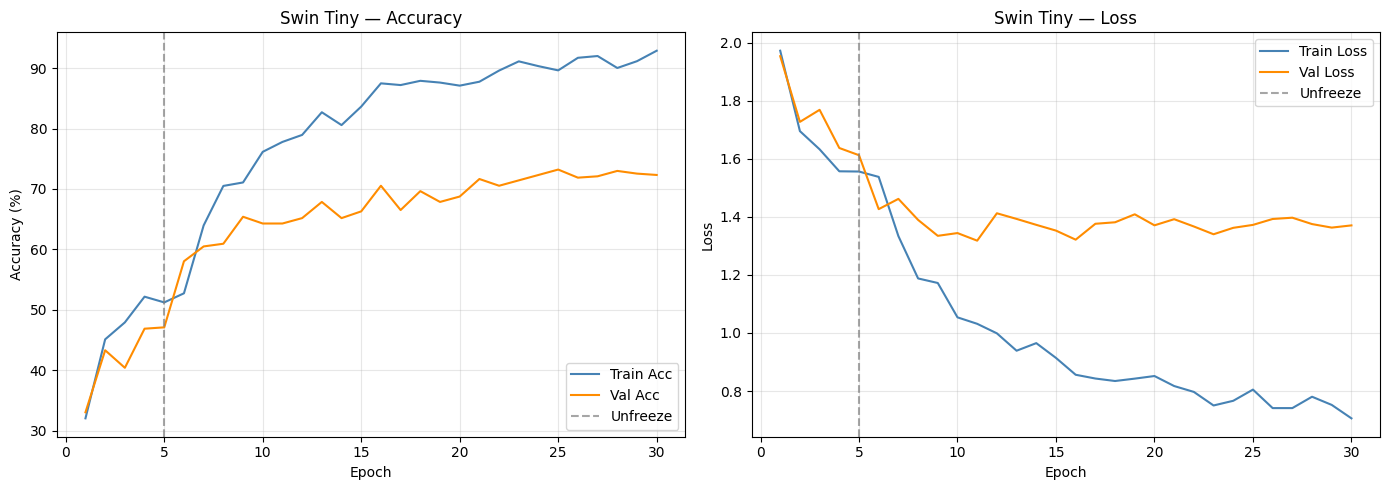

Plot saved: /content/drive/MyDrive/swin_tiny_accuracy_loss.png

Classification Report (Best Model — Validation Set)
                            precision    recall  f1-score   support

         actinic keratosis     0.2258    0.3043    0.2593        23
      basal cell carcinoma     0.8795    0.9733    0.9241        75
            dermatofibroma     0.8095    0.8947    0.8500        19
                  melanoma     0.7534    0.6250    0.6832        88
                     nevus     0.6923    0.6338    0.6618        71
pigmented benign keratosis     0.8750    0.8280    0.8508        93
      seborrheic keratosis     0.0476    0.0667    0.0556        15
   squamous cell carcinoma     0.6842    0.7222    0.7027        36
           vascular lesion     0.9643    0.9643    0.9643        28

                  accuracy                         0.7321       448
                 macro avg     0.6591    0.6680    0.6613       448
              weighted avg     0.7494    0.7321    0.7384       44

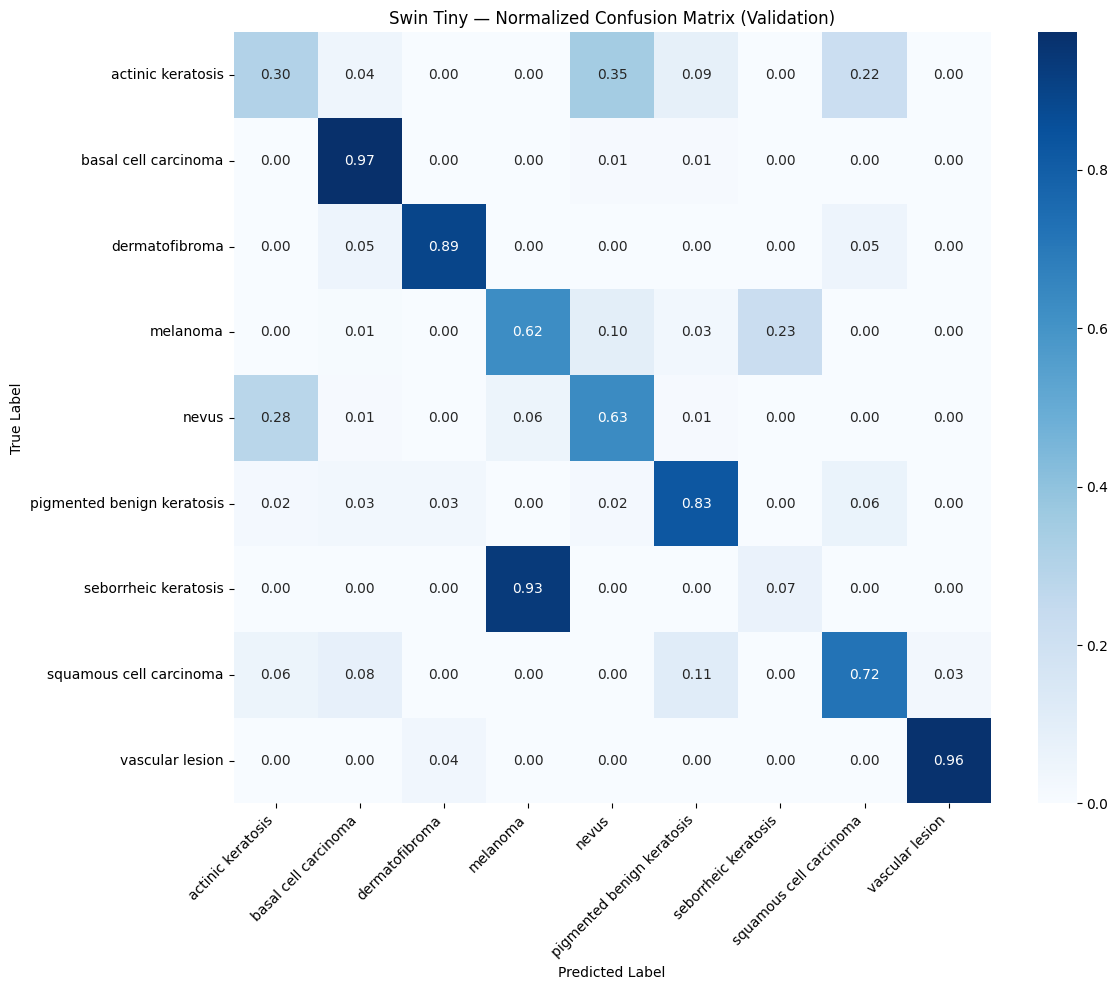

Confusion matrix saved: /content/drive/MyDrive/swin_tiny_confusion_matrix.png

Grad-CAM Visualization


RuntimeError: The size of tensor a (768) must match the size of tensor b (49) at non-singleton dimension 1

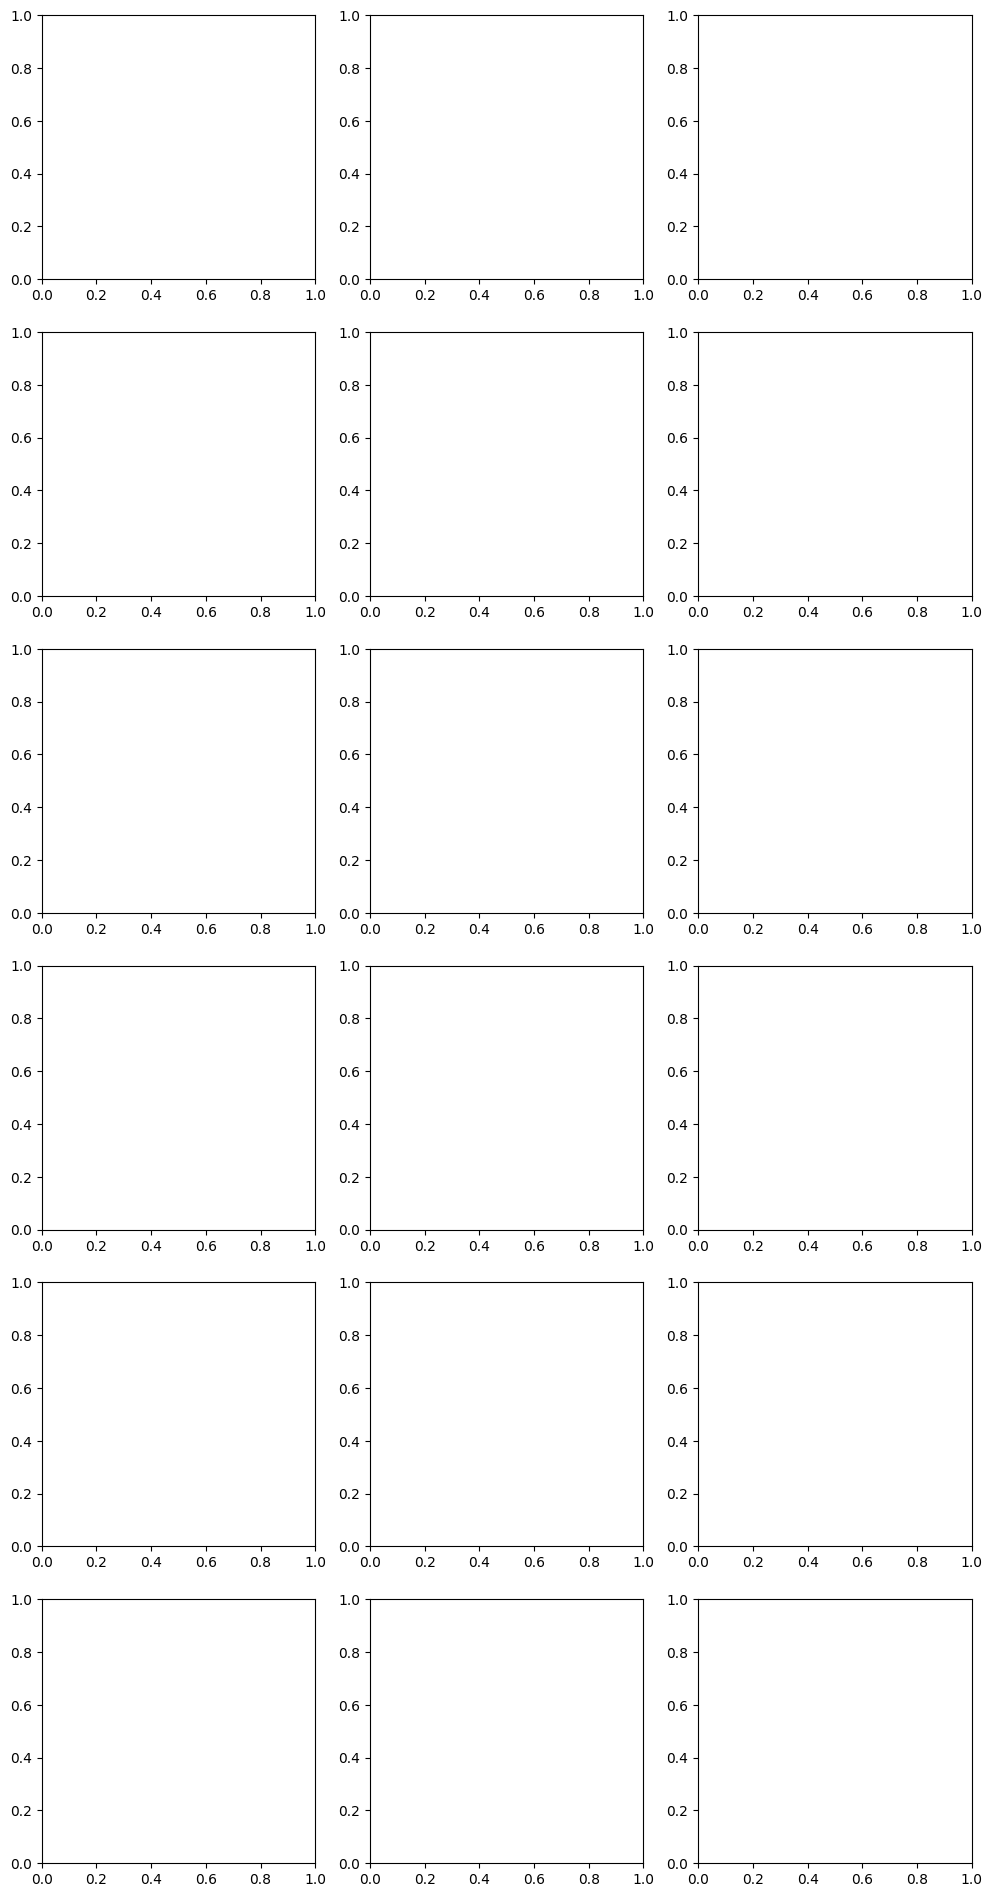

In [8]:
# =====================================================================
# Swin Tiny - Skin Cancer ISIC - 9-Class Classification
# Google Colab Ready | Optimized for 2239 images, 9 classes
# =====================================================================

# !pip install timm albumentations scikit-learn seaborn opencv-python-headless

# =====================================
# Mount Google Drive
# =====================================
from google.colab import drive
drive.mount('/content/drive')

# =====================================
# Imports
# =====================================
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedShuffleSplit
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import GradScaler, autocast

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

# =====================================
# Reproducibility
# =====================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# =====================================
# Config
# =====================================
DATASET_PATH    = "/content/drive/MyDrive/Skin cancer ISIC Dataset/Train"
MODEL_SAVE_PATH = "/content/drive/MyDrive/swin_tiny_skin_cancer_best.pth"
PLOT_SAVE_PATH  = "/content/drive/MyDrive/swin_tiny_accuracy_loss.png"
CM_SAVE_PATH    = "/content/drive/MyDrive/swin_tiny_confusion_matrix.png"
GRADCAM_SAVE    = "/content/drive/MyDrive/swin_tiny_gradcam.png"

IMG_SIZE         = 224
BATCH_SIZE       = 8
EPOCHS           = 30
FREEZE_EPOCHS    = 5
LR_HEAD          = 1e-3
LR_BACKBONE      = 5e-5
LR_HEAD_FT       = 1e-4
WEIGHT_DECAY     = 0.01
DROPOUT          = 0.3
LABEL_SMOOTHING  = 0.1
PATIENCE         = 5
MIXUP_ALPHA      = 0.2
MIXUP_PROB       = 0.5
VAL_SPLIT        = 0.2
NUM_CLASSES      = 9
MODEL_NAME       = "swin_tiny_patch4_window7_224"

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# =====================================
# Augmentations (dermoscopy-appropriate)
# =====================================
def make_train_transform(img_size):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
        A.CoarseDropout(
            num_holes_range=(1, 6),
            hole_height_range=(12, 28),
            hole_width_range=(12, 28),
            fill=0,
            p=0.3,
        ),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


def make_val_transform(img_size):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


train_transform = make_train_transform(IMG_SIZE)
val_transform   = make_val_transform(IMG_SIZE)

# =====================================
# Dataset
# =====================================
class SkinCancerDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir     = root_dir
        self.transform    = transform
        self.image_paths  = []
        self.labels       = []
        self.class_names  = sorted([
            d for d in os.listdir(root_dir)
            if os.path.isdir(os.path.join(root_dir, d))
        ])
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.class_names)}

        for cls in self.class_names:
            cls_folder = os.path.join(root_dir, cls)
            for img_file in os.listdir(cls_folder):
                if img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')):
                    self.image_paths.append(os.path.join(cls_folder, img_file))
                    self.labels.append(self.class_to_idx[cls])

        print(f"Total images: {len(self.image_paths)}")
        print(f"Classes ({len(self.class_names)}): {self.class_names}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label    = self.labels[idx]
        image    = np.array(Image.open(img_path).convert("RGB"))
        if self.transform:
            image = self.transform(image=image)["image"]
        return image, label


class SubsetWithTransform(Dataset):
    def __init__(self, dataset, indices, transform):
        self.dataset   = dataset
        self.indices   = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img_path = self.dataset.image_paths[real_idx]
        label    = self.dataset.labels[real_idx]
        image    = np.array(Image.open(img_path).convert("RGB"))
        if self.transform:
            image = self.transform(image=image)["image"]
        return image, label

# =====================================
# MixUp
# =====================================
def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    index = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1.0 - lam) * x[index]
    return mixed_x, y, y[index], lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1.0 - lam) * criterion(pred, y_b)

# =====================================
# Model
# =====================================
class SwinSkinCancer(nn.Module):
    def __init__(self, num_classes=9, dropout=0.3, model_name=MODEL_NAME):
        super().__init__()
        self.backbone = timm.create_model(
            model_name,
            pretrained=True,
            num_classes=0,
            drop_rate=dropout,
            drop_path_rate=0.1,
        )
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(dropout),
            nn.Linear(feat_dim, num_classes),
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.head(features)


def set_backbone_trainable(model, trainable):
    for param in model.backbone.parameters():
        param.requires_grad = trainable


def build_optimizer(model, phase="head"):
    if phase == "head":
        return optim.AdamW(
            model.head.parameters(),
            lr=LR_HEAD,
            weight_decay=WEIGHT_DECAY,
        )
    backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
    head_params     = list(model.head.parameters())
    return optim.AdamW(
        [
            {"params": backbone_params, "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY},
            {"params": head_params,     "lr": LR_HEAD_FT,  "weight_decay": WEIGHT_DECAY},
        ],
        weight_decay=WEIGHT_DECAY,
    )

# =====================================
# Grad-CAM for Swin Transformer
# =====================================
class SwinGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._fh = target_layer.register_forward_hook(self._forward_hook)
        self._bh = target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inputs, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[0, class_idx]
        score.backward()

        grads = self.gradients
        acts  = self.activations

        if grads is None or acts is None:
            raise RuntimeError("Grad-CAM hooks did not capture tensors.")

        if acts.dim() == 3:
            weights = grads.mean(dim=1)
            cam = (weights.unsqueeze(-1) * acts).sum(dim=1)
            b, hw = cam.shape
            side = int(hw ** 0.5)
            cam = cam.view(b, side, side)
        elif acts.dim() == 4:
            weights = grads.mean(dim=(2, 3), keepdim=True)
            cam = (weights * acts).sum(dim=1)
        else:
            raise ValueError(f"Unexpected activation shape: {acts.shape}")

        cam = torch.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam[0].cpu().numpy(), class_idx, output.softmax(dim=1)[0, class_idx].item()

    def remove_hooks(self):
        self._fh.remove()
        self._bh.remove()


def overlay_gradcam(image_rgb, cam, alpha=0.45):
    h, w = image_rgb.shape[:2]
    cam_resized = cv2.resize(cam, (w, h))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = (alpha * heatmap + (1.0 - alpha) * image_rgb).astype(np.uint8)
    return overlay

# =====================================
# Load Data — Stratified Split
# =====================================
full_dataset = SkinCancerDataset(DATASET_PATH, transform=None)
all_labels   = np.array(full_dataset.labels)

sss = StratifiedShuffleSplit(n_splits=1, test_size=VAL_SPLIT, random_state=42)
train_idx, val_idx = next(sss.split(np.zeros(len(all_labels)), all_labels))

train_dataset = SubsetWithTransform(full_dataset, train_idx, train_transform)
val_dataset   = SubsetWithTransform(full_dataset, val_idx, val_transform)

train_labels   = [full_dataset.labels[i] for i in train_idx]
class_counts   = np.bincount(train_labels, minlength=NUM_CLASSES)
class_weights  = 1.0 / np.maximum(class_counts, 1)
sample_weights = [class_weights[l] for l in train_labels]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Class counts (train): {class_counts}")

# =====================================
# Model, Loss, Scaler
# =====================================
model = SwinSkinCancer(num_classes=NUM_CLASSES, dropout=DROPOUT).to(DEVICE)
print(f"Model: {MODEL_NAME} | Params: {sum(p.numel() for p in model.parameters()):,}")

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
scaler    = GradScaler()

set_backbone_trainable(model, trainable=False)
optimizer = build_optimizer(model, phase="head")
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FREEZE_EPOCHS, eta_min=1e-6)

# =====================================
# Train / Validate
# =====================================
def train_one_epoch(model, loader, optimizer, criterion, scaler, device, use_mixup=True):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for batch_idx, (images, labels) in enumerate(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        apply_mixup = use_mixup and (random.random() < MIXUP_PROB)
        if apply_mixup:
            images, y_a, y_b, lam = mixup_data(images, labels, MIXUP_ALPHA)

        optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = model(images)
            loss = (
                mixup_criterion(criterion, outputs, y_a, y_b, lam)
                if apply_mixup
                else criterion(outputs, labels)
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        _, predicted = outputs.max(1)
        if apply_mixup:
            correct += (lam * predicted.eq(y_a).sum().item()
                        + (1.0 - lam) * predicted.eq(y_b).sum().item())
        else:
            correct += predicted.eq(labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 20 == 0:
            print(f"  Step [{batch_idx + 1}/{len(loader)}]  "
                  f"Loss: {total_loss / (batch_idx + 1):.4f}  "
                  f"Acc: {100.0 * correct / total:.2f}%")

    return total_loss / len(loader), 100.0 * correct / total


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        total_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total   += labels.size(0)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return total_loss / len(loader), 100.0 * correct / total, all_preds, all_labels

# =====================================
# Training Loop
# =====================================
best_val_acc = 0.0
patience_ctr = 0
best_val_preds, best_val_labels = [], []
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

print("\n" + "=" * 60)
print(f"Phase 1: Frozen Backbone ({FREEZE_EPOCHS} epochs) — Head Only")
print("=" * 60)

for epoch in range(1, EPOCHS + 1):
    if epoch == FREEZE_EPOCHS + 1:
        print("\n" + "=" * 60)
        print("Phase 2: Unfreeze Backbone — Full Fine-Tuning")
        print("=" * 60)
        set_backbone_trainable(model, trainable=True)
        optimizer = build_optimizer(model, phase="full")
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=EPOCHS - FREEZE_EPOCHS, eta_min=1e-6
        )

    phase = "frozen" if epoch <= FREEZE_EPOCHS else "full"
    current_lr = optimizer.param_groups[0]["lr"]
    print(f"\nEpoch [{epoch}/{EPOCHS}]  Phase: {phase}  LR: {current_lr:.2e}")

    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, DEVICE, use_mixup=True
    )
    val_loss, val_acc, val_preds, val_labels = validate(
        model, val_loader, criterion, DEVICE
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    gap = train_acc - val_acc
    print(f"  Train — Loss: {train_loss:.4f}  Acc: {train_acc:.2f}%")
    print(f"  Val   — Loss: {val_loss:.4f}  Acc: {val_acc:.2f}%  [Gap: {gap:.1f}%]")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_ctr = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "val_acc": val_acc,
                "class_names": full_dataset.class_names,
                "model_name": MODEL_NAME,
            },
            MODEL_SAVE_PATH,
        )
        best_val_preds  = val_preds
        best_val_labels = val_labels
        print(f"  Best model saved! Val Acc: {val_acc:.2f}%")
    else:
        patience_ctr += 1
        print(f"  No improvement ({patience_ctr}/{PATIENCE})")
        if patience_ctr >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch}.")
            break

print(f"\nTraining complete. Best Val Accuracy: {best_val_acc:.2f}%")

# =====================================
# Load Best Checkpoint
# =====================================
checkpoint = torch.load(MODEL_SAVE_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded best checkpoint from epoch {checkpoint['epoch']} "
      f"(Val Acc: {checkpoint['val_acc']:.2f}%)")

val_loss, val_acc, best_val_preds, best_val_labels = validate(
    model, val_loader, criterion, DEVICE
)

# =====================================
# Accuracy / Loss Plots
# =====================================
epochs_range = list(range(1, len(history["train_acc"]) + 1))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_acc"], label="Train Acc", color="steelblue")
plt.plot(epochs_range, history["val_acc"],   label="Val Acc",   color="darkorange")
plt.axvline(x=FREEZE_EPOCHS, color="gray", linestyle="--", alpha=0.7, label="Unfreeze")
plt.title("Swin Tiny — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_loss"], label="Train Loss", color="steelblue")
plt.plot(epochs_range, history["val_loss"],   label="Val Loss",   color="darkorange")
plt.axvline(x=FREEZE_EPOCHS, color="gray", linestyle="--", alpha=0.7, label="Unfreeze")
plt.title("Swin Tiny — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_SAVE_PATH, dpi=150)
plt.show()
print(f"Plot saved: {PLOT_SAVE_PATH}")

# =====================================
# Classification Report
# =====================================
print("\n" + "=" * 60)
print("Classification Report (Best Model — Validation Set)")
print("=" * 60)
print(classification_report(
    best_val_labels,
    best_val_preds,
    target_names=full_dataset.class_names,
    digits=4,
))

# =====================================
# Confusion Matrix
# =====================================
cm = confusion_matrix(best_val_labels, best_val_preds)
cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=full_dataset.class_names,
    yticklabels=full_dataset.class_names,
)
plt.title("Swin Tiny — Normalized Confusion Matrix (Validation)")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(CM_SAVE_PATH, dpi=150)
plt.show()
print(f"Confusion matrix saved: {CM_SAVE_PATH}")

# =====================================
# Grad-CAM Visualization
# =====================================
print("\n" + "=" * 60)
print("Grad-CAM Visualization")
print("=" * 60)

target_layer = model.backbone.layers[-1].blocks[-1].norm2
gradcam = SwinGradCAM(model, target_layer)

num_samples = min(6, len(val_dataset))
sample_indices = random.sample(range(len(val_dataset)), num_samples)

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

model.eval()
for row, subset_idx in enumerate(sample_indices):
    real_idx = val_dataset.indices[subset_idx]
    img_path = full_dataset.image_paths[real_idx]
    true_label = full_dataset.labels[real_idx]
    raw_img = np.array(Image.open(img_path).convert("RGB"))
    display_img = cv2.resize(raw_img, (IMG_SIZE, IMG_SIZE))

    tensor = val_transform(image=raw_img)["image"].unsqueeze(0).to(DEVICE)

    cam, pred_label, pred_conf = gradcam.generate(tensor, class_idx=None)
    overlay = overlay_gradcam(display_img, cam)

    true_name = full_dataset.class_names[true_label]
    pred_name = full_dataset.class_names[pred_label]

    axes[row, 0].imshow(display_img)
    axes[row, 0].set_title(f"Original\nTrue: {true_name}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cam, cmap="jet")
    axes[row, 1].set_title("Grad-CAM Heatmap")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f"Overlay\nPred: {pred_name} ({pred_conf:.2f})")
    axes[row, 2].axis("off")

gradcam.remove_hooks()
plt.tight_layout()
plt.savefig(GRADCAM_SAVE, dpi=150)
plt.show()
print(f"Grad-CAM saved: {GRADCAM_SAVE}")

# =====================================
# Summary
# =====================================
print("\n" + "=" * 60)
print("All Done!")
print(f"Best Validation Accuracy : {best_val_acc:.2f}%")
print(f"Model saved at           : {MODEL_SAVE_PATH}")
print("=" * 60)
